In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
import math
import scipy
import scipy.stats

random.seed(42)
np.random.seed(42)

## Brouillon

$$\dfrac{dx_i}{dt} = -x_i - g \dfrac{1}{\sqrt{n}} \sum_{j=1}^{n}( w_{i,j} R(x_j)) + I_i$$

- A l'équilibre :
$$ x_i = - g \dfrac{1}{\sqrt{n}} \sum_{j=1}^{n}( w_{i,j} R(x_j)) + I_i $$

$$\dfrac{1}{\sqrt{n}} \sum_{j=1}^{n}( w_{i,j} R(x_j)) = \sqrt{n}\langle W_{i,j} R(x_j) \rangle =  \sqrt{n}\langle W_{i,j}\rangle \langle R(x_j) \rangle $$
en supposant que les $w$ et $R(x)$ sont indépendants (ce qui n'est pas tout à fait vrai)

- A l'équilibre (i.e $\dfrac{dX}{dt} = 0$), en appelant $X^*$ le réseau à l'équilibre :
$$x_i^* = I_i - g \cdot \sqrt{n} \langle W_{i,j}\rangle \langle R(x^*_j) \rangle $$

- En posant $ a= g \cdot \sqrt{n} \langle W_{i,j}\rangle \langle R(x^*_j) \rangle$ on a $X^* = I - a$ donc :

$$ \displaystyle \int_{0}^{1} {R(x_{i,j}) dj} = \displaystyle \int_{a}^{1} {I-a dj}$$

car $R$ est la fonction $ReLU$

- A une petite variation de l'état d'équilibre, d'après la formule de Taylor-Young : 
$$f(x_i^* + \delta x_i) = f(x_i^*)+ f'(x_i^*)\delta x_i + o(\delta x_i)$$

- rappel Taylor-Young: $f(a+h)=f(a)+f'(a) h+\dots+\frac{f^{(n)}(a)}{n!}h^n+o(h^n)$

----------
 - En posant $x_i = x_i^* + \delta x_i$ :
   $$ \dfrac{dx_i}{dt} = -x_i^* - \delta x_i - g \dfrac{1}{\sqrt{n}} \sum_{j=1}^{n}( w_{i,j} (R(x_j^*)+R'(x_j+ \delta x_j))) + I_i$$
   car $R(x_i^*+\delta x_i)-R(x_i^*) = R'(x_i^*)\delta x_i $
   $$ \iff  \dfrac{d \delta x_i}{dt} = \underbrace{ -x_i^* - g \dfrac{1}{\sqrt{n}} \sum_{j=1}^{n}( w_{i,j} R(x_j^*)) + I_i}_{=0 \text{ car } x_i^* \text{ est un point fixe}} - \delta x_i - g \dfrac{1}{\sqrt{n}} \sum_{j=1}^{n}( w_{i,j} R'(x_j^*)\delta x_j)$$
   Donc :
    $$ \dfrac{d \delta x_i}{dt} = - \delta x_i - g \dfrac{1}{\sqrt{n}} \sum_{j=1}^{n}( w_{i,j} R'(x_j^*)\delta x_j)$$


## Cas 1

### Modèle

On pose : $$ \dfrac{dX}{dt} = -X + gWR(X) + I$$
Avec :
- $X$ qui représente la différence de potentiel des neurones du réseau ;
- $g$ qui contrôle la force des connexions ; 
- $W$ une matrice aléatoire telle que : $w_{i,j} \sim \mathcal{N} \left(0,\dfrac{1}{N^2} \right)$ qui représente les forces des synapses des neurones du réseau. On conservera uniquement les $W_{i,j} < 0$ (on se place dans le cadre d'un réseau avec uniquement des synapses inhibitrices) ; 
- $R(X)$ le taux de décharge que l'on assimile a la fonction $ReLU$ ;
- $I$ une entrée externe constante (activatrice, avec la même valeur positive pour tous les neurones)

### Simulation

On défini $X$ (pour $n$ unités de type neuronal) :

In [2]:
n = 100

In [3]:
def exemple_X(n):
    X = [random.uniform(-0.5,0.5) for i in range(n)]
    X = np.array(X)
    return X

On crée $W$ avec uniquement des synapses inhibitrices :

In [4]:
def W_inhib(n):
    W = []
    w = []
    i=0
    for j in range(n):
        while i<n :
            x = random.gauss(0,1/(n))
            if x <= 0 :
                w.append(x)
                i+=1
        W.append(w)
        w=[]
        i=0
    W = np.array(W)
    return W

On défini le taux de décharge : 

In [5]:
def R_relu(X) :
    return np.maximum(X,0)

On défini $I$ excitateur :

In [6]:
i = 0.6

In [7]:
def I(n,i):
    return np.array([i for j in range (n)])

On défini les paramètres de la simulation :

In [8]:
g = 1.2
t_0 = 0
W = W_inhib(n)
I_n = I(n,i)
X_0 = exemple_X(n)
h = 0.01
T = 10

On défini l'équation différentielle :

In [9]:
def f(X,g,W,I_n) :
    return -X+g* ( W @ R_relu(X)) + I_n

On trace le graphique :

In [10]:
def Euler_O1(f,t_0,X_0,h,T,g,W,I_n):
    Images_Euler = [X_0]
    Atcd_Euler = [t_0]
    X = X_0
    t = t_0
    for i in range (int((T-t_0)/h)): 
        X = h * f(X,g,W,I_n) + X  
        t += h
        Images_Euler.append(X)
        Atcd_Euler.append(t)
    return Atcd_Euler,Images_Euler

In [11]:
def graph_O1(f,t_0,X_0,h,T,g,W,I_n):
    Atcd_Euler,Images_Euler = Euler_O1(f,t_0,X_0,h,T,g,W,I_n)
    plt.figure(figsize =(8,6))
    for i in range (len(X_0)):
        plt.plot(Atcd_Euler,[X[i] for X in Images_Euler] )
    plt.show()

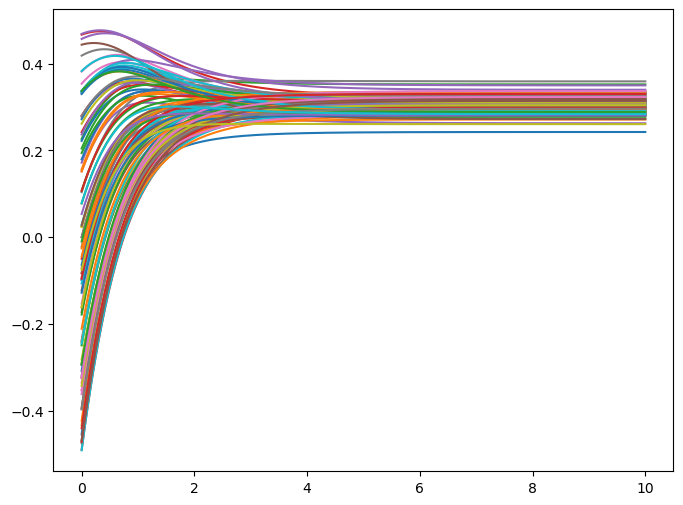

In [12]:
graph_O1(f,t_0,X_0,h,T,g,W,I_n)


- Les $w_{i_j} \sim \mathcal{n} \left(0,\dfrac{1}{n^2} \right)$ mais les valeurs tirées pour les $w_{i,j}$ sont conservées que si elles sont négatives donc :

Comme pour $w_{i_j} \sim \mathcal{n} \left(0,\dfrac{1}{n^2} \right)$ la densité de probabilité vaut $f(w) = \dfrac{1}{\sigma \sqrt{2 \pi}} e^ {\frac{-w^2}{2 \sigma^2}}$, l'espérance des $w$ vaut : $\int_{- \infty}^{+ \infty} {w \dfrac{1}{\sigma \sqrt{2 \pi}}} e^{\dfrac{-w^2}{2 \sigma^2}} dw$ donc:
 
$$ \mathbb{E} (w | w < 0) = \dfrac {\int_{- \infty}^{0} {w \dfrac{1}{\sigma \sqrt{2 \pi}}} e^{\dfrac{-w^2}{2 \sigma^2}} dw} {P(w<0)}$$

$$\mathbb{E}(w\mid w<0)=\dfrac{\dfrac{-\sigma}{\sqrt{2\pi}}}{\dfrac{1}{2}} = - \sqrt{ \dfrac{2}{\pi}} \sigma $$

Donc $\sum_{j=1}^{n}w_{i,j}$ est d'ordre $n \left ( - \dfrac 1 n \sqrt{\dfrac{2}{\pi}} \right ) = - \sqrt{\dfrac {2}{\pi}}$. 

- Supposons que les $x_i$ convergent vers un même point fixe $x^*$ :
   $$ x^* =g \sum_{j=1}^{n}( w_{i,j} R(x_j)) + I_i $$
  $$ x^* \sim - g \sqrt{\dfrac {2}{\pi}} R(x^*)+I_i$$
  $x^*$ est positif (si on suppose $x^*$ négatif on arrive à une contradiction : $x^* = I_i$) donc :
  $$ x^* \sim - g \sqrt{\dfrac {2}{\pi}} x^*+I_i$$
  $$\iff x^* \sim \dfrac{I_i}{1 + g \sqrt{\dfrac {2}{\pi}}}$$
  


In [13]:
def histogramme_X_I(f,t_0,X_0,h,T,g,W,I_n):
    Atcd_Euler,Images_Euler = Euler_O1(f,t_0,X_0,h,T,g,W,I_n)
    plt.xlabel("Valeurs des X_i après T")
    plt.ylabel("Densité de proba")
    plt.hist(Images_Euler[-1], bins = 10, density = True)
    plt.axvline(x= (I_n[0])/(1+g * np.sqrt(2/np.pi)), label = "limite",color = "red")
    plt.legend()

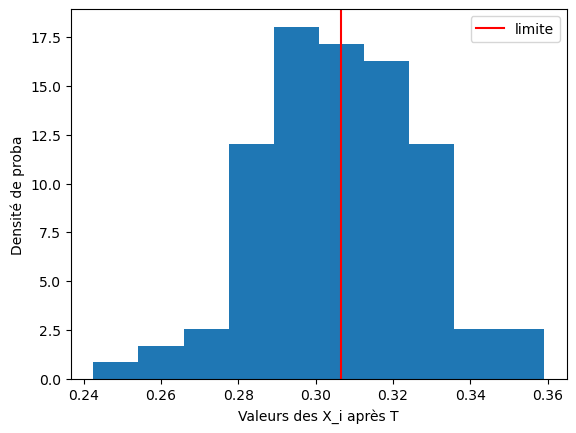

In [14]:
histogramme_X_I(f,t_0,X_0,h,T,g,W,I_n)

In [15]:
def histogramme_R(f,t_0,X_0,h,T,g,W,I_n):
    Atcd_Euler,Images_Euler = Euler_O1(f,t_0,X_0,h,T,g,W,I_n)
    plt.xlabel("Valeurs des R(X_i) après T")
    plt.ylabel("Effectifs")
    plt.hist(R_relu(Images_Euler[-1]), bins = 10, density = True)

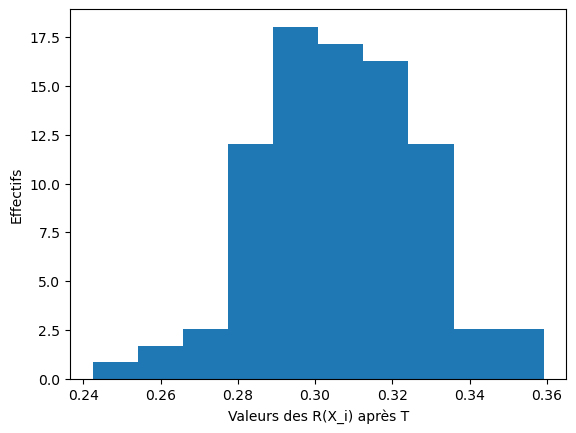

In [16]:
histogramme_R(f,t_0,X_0,h,T,g,W,I_n)

On voit que les $x_i$ tendent bien vers la limite théorique.

## Cas $1$ bis

On prend $W \sim \mathcal{N} \left(0,\dfrac{1}{N^3} \right)$

In [17]:
def W_inhib_bis(n):
    W = []
    w = []
    i=0
    for j in range(n):
        while i<n :
            x = random.gauss(0,1/(n**(1.5)))
            if x <= 0 :
                w.append(x)
                i+=1
        W.append(w)
        w=[]
        i=0
    W = np.array(W)
    return W

In [18]:
W = W_inhib_bis(n)

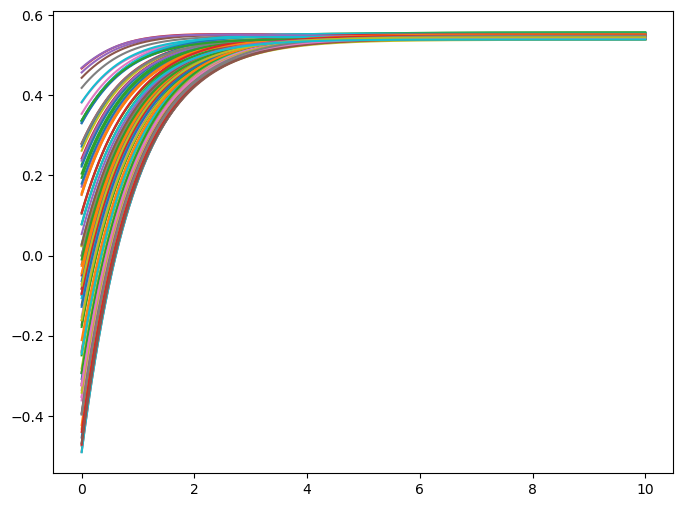

In [19]:
graph_O1(f,t_0,X_0,h,T,g,W,I_n)

Comme $W \sim \mathcal{n} \left(0,\dfrac{1}{n^3} \right)$, et que $\dfrac{dx_i}{dt} = -x_i +  g \sum_{j=1}^{n}( w_{i,j} R(x_j)) + I_i$ :

$g \sum_{j=1}^{n}( w_{i,j} R(x_j))$ est d'ordre $ \dfrac {1}{\sqrt{n}}$.

Donc quand $n \to +\infty$ :

${g \sum_{j=1}^{n}( w_{i,j} R(x_j))} \to 0$ et ${\dfrac{dx_i}{dt}} \to -x_i + I_i$

Donc à l'équilibre i.e ${\dfrac{dx_i}{dt}}=0$ :

$x_i \to I_i$,

et comme $I_i$ est le même pour tous les neurones, tous les $x_i$ convergent vers $I$ quand $n \to +\infty$.

In [20]:
def histogramme_X_I(f,t_0,X_0,h,T,g,W,I_n):
    Atcd_Euler,Images_Euler = Euler_O1(f,t_0,X_0,h,T,g,W,I_n)
    plt.xlabel("Valeurs des X_i après T")
    plt.ylabel("Densité de proba")
    plt.hist(Images_Euler[-1], bins = 5, density = True)
    plt.axvline(x=i, label = "I",color = "red")
    plt.legend()

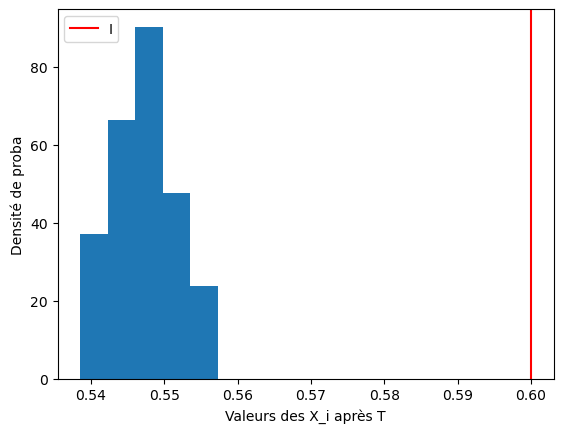

In [21]:
histogramme_X_I(f,t_0,X_0,h,T,g,W,I_n)

## Cas $2$

### Modèle

On pose : $$ \dfrac{dX}{dt} = -X + gWR(X) + I$$
Avec :
- $X$ qui représente la différence de potentiel des neurones du réseau ;
- $g$ qui contrôle la force des connexions ; 
- $W$ une matrice aléatoire telle que : $W \sim \mathcal{N} \left(0,\dfrac{1}{N^3} \right)$ qui représente les forces des synapses des neurones du réseau. On conservera uniquement les $W_{i,j} < 0$ (on se place dans le cadre d'un réseau avec uniquement des synapses inhibitrices) ; **Ou 1/n^2 ?**
- $R(X)$ le taux de décharge que l'on assimile a la fonction $ReLU$ ;
- $I$ une entrée externe constante (activatrice, avec des valeurs différentes comprises dans l'intervalle $[0;1]$ pour tous les neurones)

### Simulation - $W \sim \mathcal{N} \left(0,\dfrac{1}{N^3} \right)$

On défini $I$ :

In [22]:
def I_var(n):
    return np.array([random.uniform(0,1) for i in range (n)])

In [23]:
I_n = I_var(n)
W = W_inhib_bis(n)

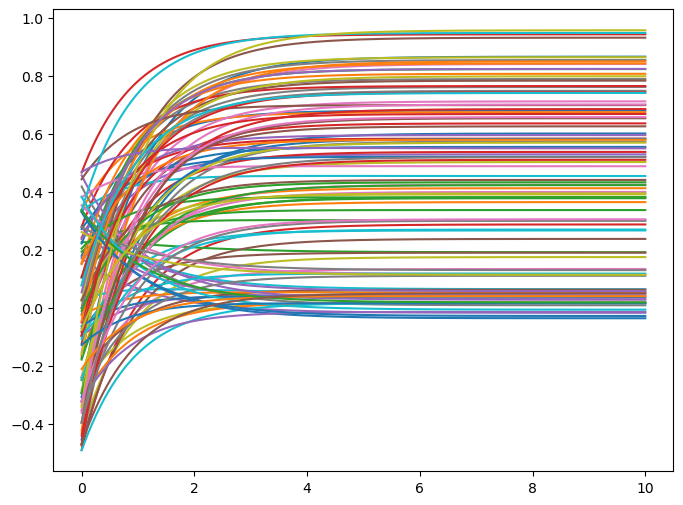

In [24]:
graph_O1(f,t_0,X_0,h,T,g,W,I_n)

In [25]:
def histogramme_X_bornes(f,t_0,X_0,h,T,g,W,I_n):
    Atcd_Euler,Images_Euler = Euler_O1(f,t_0,X_0,h,T,g,W,I_n)
    plt.xlabel("Valeurs des X_i après T")
    plt.ylabel("Densité de proba")
    plt.hist(Images_Euler[-1], bins = 5, density = True)
    plt.axvline(x= min(I_n),label = "Valeur min de I",color = "black")
    plt.axvline(x= max(I_n),label = "Valeur max de I",color = "black")
    plt.legend()

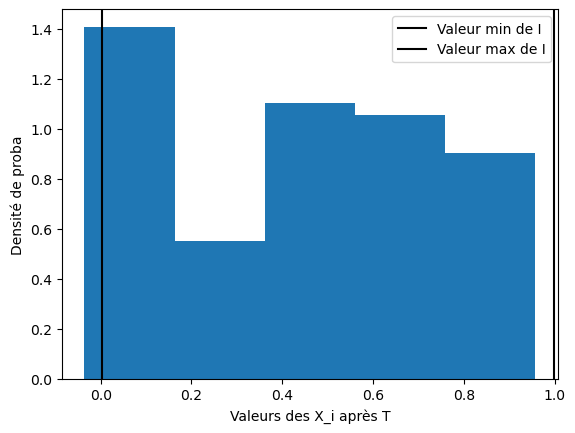

In [26]:
histogramme_X_bornes(f,t_0,X_0,h,T,g,W,I_n)

Comme dans le cas précédent quand $n \to +\infty$ :

${g \sum_{j=1}^{n}( w_{i,j} R(x_j))} \to 0$ et ${\dfrac{dx_i}{dt}} \to -x_i + I_i$

Donc quand $n \to +\infty$, à l'équilibre, on a :

$x_i \to I_i$ 



### Simulation - $W \sim \mathcal{N} \left(0,\dfrac{1}{N^2} \right)$

In [27]:
W = W_inhib(n)

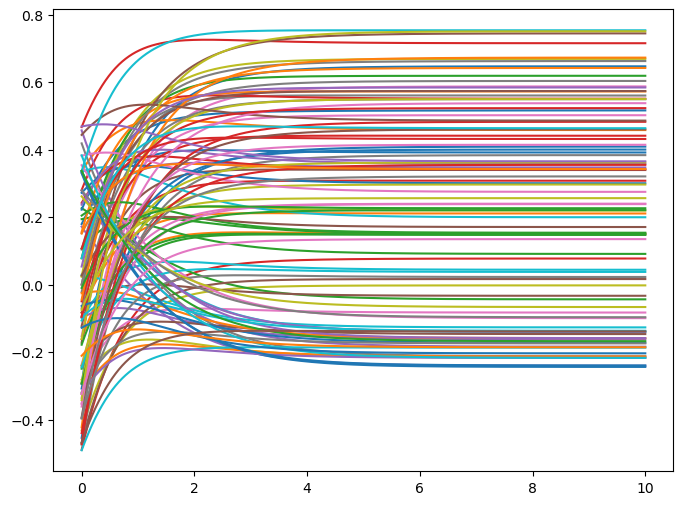

In [28]:
graph_O1(f,t_0,X_0,h,T,g,W,I_n)

A l'équilibre : 
$$x_i^* = g \sum_{j=1}^{n}( w_{i,j} R(x_j)) + I_i $$
$$ \iff x_i^* = - g \sqrt{\dfrac {2}{\pi}}\dfrac 1 n \sum_{j=1}^{n} R(x_j) + I_i $$ en utilisant le fait que $\sum_{j=1}^{n}w_{i,j}$ est d'ordre $ - \sqrt{\dfrac {2}{\pi}}$ (cf section "Cas $1$")
$$ \iff x_i^* = - g \sqrt{\dfrac {2}{\pi}} \langle R(x_j)\rangle + I_i $$
En posant $m= \langle R(x_j)\rangle$ on a :
$$m = \dfrac 1 n \sum_{j=1}^{n} R(x_j^*)  $$
$$ \iff m = \dfrac 1 n \sum_{j=1}^{n} R \left(I_j - g \sqrt{\dfrac {2}{\pi}} m \right) $$
$$ m = \displaystyle \int_{0}^{1} R \left(I_j - g \sqrt{\dfrac {2}{\pi}} m \right) dI_j$$ **mettre rappel esperance etc**
$$ m = \displaystyle \int_{g \sqrt{\frac {2}{\pi}}m}^{1} I_j - g \sqrt{\dfrac {2}{\pi}} m dI_j$$ comme $R$ est la fonction $ReLU$
$$ m = \left[ \dfrac 1 2 I_j^2 -g \sqrt{\dfrac {2}{\pi}}m I_j  \right]_{g \sqrt{\frac {2}{\pi}}m}^1$$ 
$$ m = \dfrac 1 2 - g \sqrt{\dfrac {2}{\pi}}m + \dfrac{g^2m^2}{\pi}  $$

Donc :
$$ \dfrac{g^2}{\pi} m^2 - ( 1 + g \sqrt{\dfrac {2}{\pi}}) m + \dfrac 1 2 = 0 $$
$$ \Delta = 1 + 2g \sqrt{\dfrac {2}{\pi}} $$
$$ m_{1,2}= \dfrac{1 + g \sqrt{\frac {2}{\pi}} \pm \sqrt{1 + 2g \sqrt{\frac {2}{\pi}}}}{2 \frac {g^2}{\pi}} $$

Or $g \sqrt{\frac {2}{\pi}}m$ doit être inférieur à 1 donc :
$$ m = \dfrac{1 + g \sqrt{\frac {2}{\pi}} - \sqrt{1 + 2g \sqrt{\frac {2}{\pi}}}}{2 \frac {g^2}{\pi}} $$
**détailler cf brouillon**

Donc, finalement :
$$x_i^* = - g \sqrt{\dfrac {2}{\pi}} \dfrac{1 + g \sqrt{\frac {2}{\pi}} - \sqrt{1 + 2g \sqrt{\frac {2}{\pi}}}}{2 \frac {g^2}{\pi}} + I_i$$



In [29]:
def graph_test_3(f,t_0,X_0,h,T,g,W,I_n):
    Atcd_Euler,Images_Euler = Euler_O1(f,t_0,X_0,h,T,g,W,I_n)
    plt.figure(figsize =(8,6))
    for i in range (len(X_0)):
        plt.plot(Atcd_Euler,[X[i] for X in Images_Euler] )
        plt.axhline(y = I_n[i] - g*np.sqrt(2/np.pi) *
      ((1 + g*np.sqrt(2/np.pi) - np.sqrt(1 + 2*g*np.sqrt(2/np.pi)))
       / (2*(g**2/np.pi))) ,color = "black", alpha = 0.1)

    plt.savefig("lim.pdf", bbox_inches="tight") 
    plt.show()

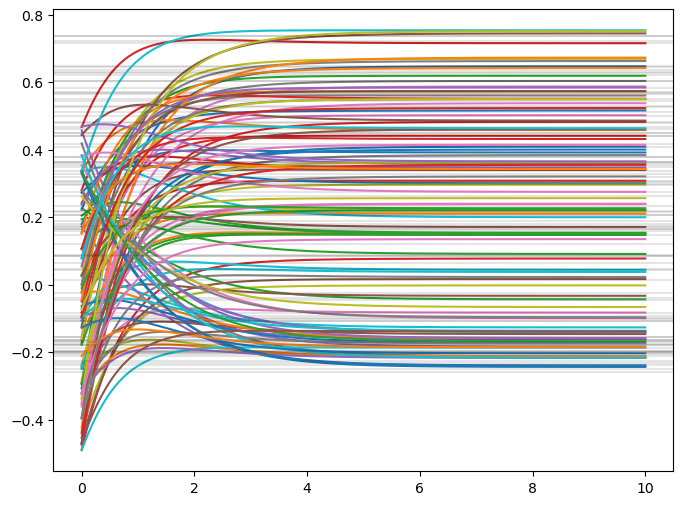

In [30]:
graph_test_3(f,t_0,X_0,h,T,g,W,I_n)

In [31]:
def histogramme_X_début_3(f,t_0,X_0,h,T,g,W,I_n):
    Atcd_Euler,Images_Euler = Euler_O1(f,t_0,X_0,h,T,g,W,I_n)
    plt.xlabel("Valeurs des X_i au début")
    plt.ylabel("Densité de proba")
    plt.hist(Images_Euler[0], bins = 10, density = True)
    #plt.axvline(x= min(I_n),label = "Valeur min de I",color = "black")
    #plt.axvline(x= max(I_n),label = "Valeur max de I",color = "black")
    plt.legend()

C:\Users\15s-eq2042\AppData\Local\Temp\ipykernel_26352\2246519376.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


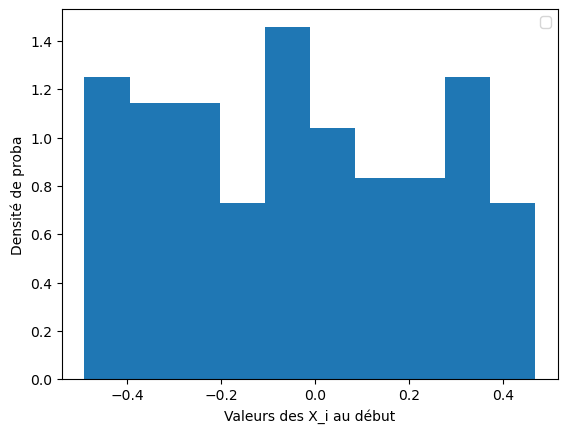

In [32]:
histogramme_X_début_3(f,t_0,X_0,h,T,g,W,I_n)

In [33]:
def histogramme_X_fin_3(f,t_0,X_0,h,T,g,W,I_n):
    Atcd_Euler,Images_Euler = Euler_O1(f,t_0,X_0,h,T,g,W,I_n)
    plt.xlabel("Valeurs des X_i au début")
    plt.ylabel("Densité de proba")
    plt.hist(Images_Euler[-1], bins = 10, density = True)
    plt.axvline(x=  np.min(I_n) - g*np.sqrt(2/np.pi) *
      ((1 + g*np.sqrt(2/np.pi) - np.sqrt(1 + 2*g*np.sqrt(2/np.pi)))
       / (2*(g**2/np.pi))),label = "Valeur min de I",color = "black")
    plt.axvline(x=  np.max(I_n) - g*np.sqrt(2/np.pi) *
      ((1 + g*np.sqrt(2/np.pi) - np.sqrt(1 + 2*g*np.sqrt(2/np.pi)))
       / (2*(g**2/np.pi))),label = "Valeur max de I",color = "black")
    plt.legend()

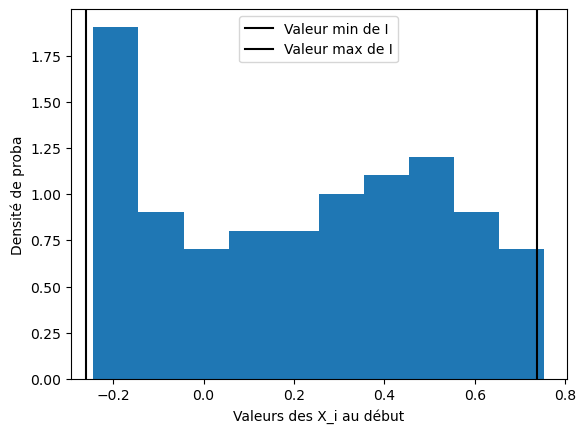

In [34]:
histogramme_X_fin_3(f,t_0,X_0,h,T,g,W,I_n)

Au début de la simulation, les $x_i$ sont dans l'intervalle $[-0,5;0,5]$ , à la fin de la simulation les $x_i$ sont dans l'intervalle $\left( - g \sqrt{\dfrac {2}{\pi}} \dfrac{1 + g \sqrt{\frac {2}{\pi}} - \sqrt{1 + 2g \sqrt{\frac {2}{\pi}}}}{2 \frac {g^2}{\pi}} + min(I_n) ; - g \sqrt{\dfrac {2}{\pi}} \dfrac{1 + g \sqrt{\frac {2}{\pi}} - \sqrt{1 + 2g \sqrt{\frac {2}{\pi}}}}{2 \frac {g^2}{\pi}} + max(I_n) \right)$

## Cas 3

### Modèle

On pose : $$ \dfrac{dX}{dt} = -X + gWR(X) + I$$
Avec :
- $X$ qui représente la différence de potentiel des neurones du réseau ;
- $g$ qui contrôle la force des connexions ; 
- $W$ une matrice aléatoire telle que : $W \sim \mathcal{N} \left(0,\dfrac{1}{n} \right)$ qui représente les forces des synapses des neurones du réseau. On conservera uniquement les $W_{i,j} < 0$ (on se place dans le cadre d'un réseau avec uniquement des synapses inhibitrices) ;
- $R(X)$ le taux de décharge que l'on assimile a la fonction $ReLU$ ;
- $I = I_0 \sqrt{n}$ avec $I_0$ une entrée externe constante (activatrice, avec la même valeur positive pour tous les neurones)

In [35]:
def I_3(n,i):
    return np.array([i for j in range (n)])

In [36]:
I_n = I_3(n,i)

In [37]:
def W_inhib_3(n):
    W = []
    w = []
    i=0
    for j in range(n):
        while i<n :
            x = random.gauss(0,1/np.sqrt(n))
            if x <= 0 :
                w.append(x)
                i+=1
        W.append(w)
        w=[]
        i=0
    W = np.array(W)
    return W

In [38]:
W = W_inhib_3(n)

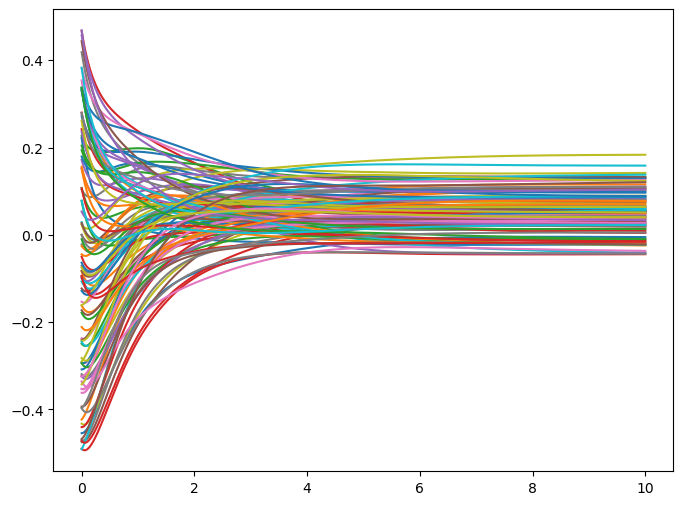

In [39]:
graph_O1(f,t_0,X_0,h,T,g,W,I_n)

In [40]:
def histogramme_X_début_3(f,t_0,X_0,h,T,g,W,I_n):
    Atcd_Euler,Images_Euler = Euler_O1(f,t_0,X_0,h,T,g,W,I_n)
    plt.xlabel("Valeurs des X_i au début")
    plt.ylabel("Densité de proba")
    plt.hist(Images_Euler[-1], bins = 10, density = True)

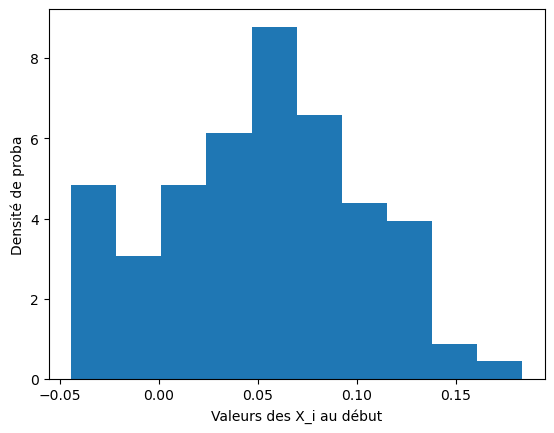

In [41]:
histogramme_X_début_3(f,t_0,X_0,h,T,g,W,I_n)

$\mathbb{E} (W | W<0) = - \sqrt{\dfrac{2}{\pi}} \cdot \dfrac{1}{\sqrt{n}} $
Donc : 
$$x_i^* = I_0\sqrt{n}- g \sqrt{\dfrac {2}{\pi}} \dfrac{1}{\sqrt n} \sum_{j=1}^{n} R(x_j) + \sum_{j=1}^{n} \epsilon_{i,j} R(x_j)$$

Car comme l'écart-type des $w_{i,j}$ vaut $\dfrac {1} {\sqrt n}$,l'écart type de $\sum_{j=1}^{n} W(x_{i,j})$ est d'ordre $\sqrt n \cdot \dfrac {1} {\sqrt n} = 1$, on ne peut plus négliger les fluctuations $\epsilon _{i,j}$ quand $n$ augmente.

$$x_i^* = \sqrt{n} ( I_0 - g \sqrt{\dfrac {2}{\pi}} m + \sum_{j=1}^{n} \epsilon_{i,j} R(x_j))$$

En posant $m = \langle R(x_j) \rangle$.


## Cas 4

### Modèle

On pose : $$ \dfrac{dX}{dt} = -X + gWR(X) + B$$
Avec :
- $X$ qui représente la différence de potentiel des neurones du réseau ;
- $g$ qui contrôle la force des connexions ; 
- $W$ une matrice aléatoire telle que : $W \sim \mathcal{N} \left(0,\dfrac{1}{N} \right)$ qui représente les forces des synapses des neurones du réseau. On conservera uniquement les $W_{i,j} < 0$ (on se place dans le cadre d'un réseau avec uniquement des synapses inhibitrices) ; 
- $R(X)$ le taux de décharge que l'on assimile a la fonction ReLU ;
- $B$ une entrée externe constante (activatrice, avec des valeurs positives différentes pour les différents neurones)

In [42]:
W = W_inhib_3(n)

In [43]:
I_n = I_var(n)

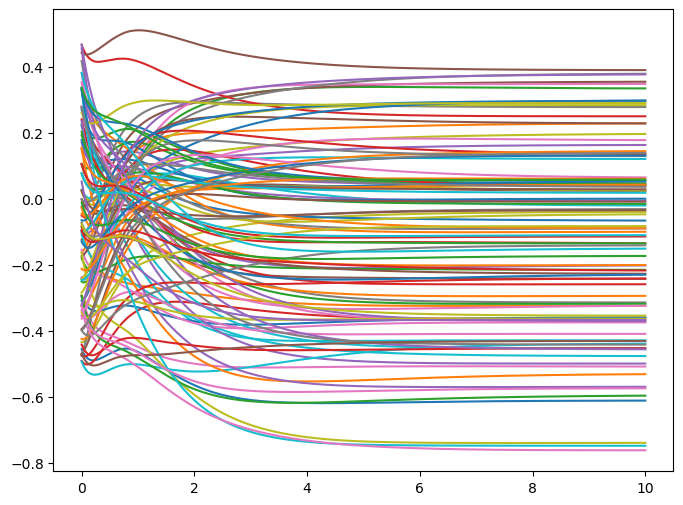

In [44]:
graph_O1(f,t_0,X_0,h,T,g,W,I_n)

$\mathbb{E} (W | W<0) = - \sqrt{\dfrac{2}{\pi}} \cdot \dfrac{1}{\sqrt{n}} $
Donc : 
$$x_i^* = I_i - g \sqrt{\dfrac {2}{\pi}} \dfrac{1}{\sqrt n} \sum_{j=1}^{n} R(x_j) + \sum_{j=1}^{n} \epsilon_{i,j} R(x_j)$$

In [45]:
def histogramme_X_3(f,t_0,X_0,h,T,g,W,I_n):
    Atcd_Euler,Images_Euler = Euler_O1(f,t_0,X_0,h,T,g,W,I_n)
    plt.xlabel("Valeurs des X_i après T")
    plt.ylabel("Densité de proba")
    plt.hist(Images_Euler[-1], bins = 10, density = True)

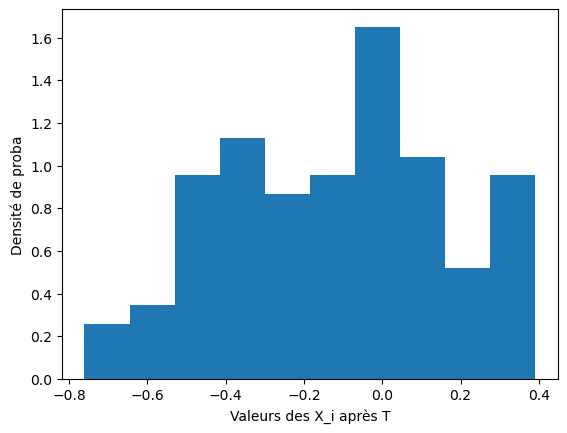

In [46]:
histogramme_X_3(f,t_0,X_0,h,T,g,W,I_n)